In [366]:
# In dev mode, run this
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [367]:
import numpy as np
import networkx as nx

import matplotlib as mpl
from matplotlib import pyplot as plt

import propnetscore.node_selection as ns
from propnetscore.plotting import plot_task

# Small graphs

## Example 1: Star graph

In [368]:
G = nx.star_graph(10)

In [369]:
G.nodes()

NodeView((0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10))

In [370]:
G.edges()

EdgeView([(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (0, 10)])

In [371]:
adjacency_matrix = nx.to_numpy_array(G, weight=None)
adjacency_matrix

array([[0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

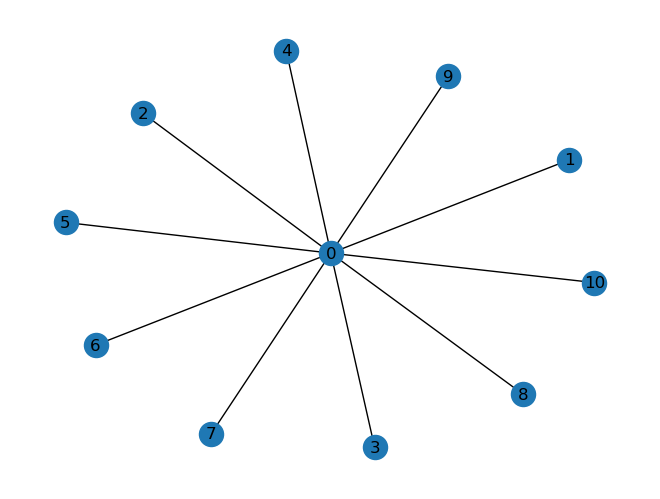

In [372]:
nx.draw(G, pos = nx.spring_layout(G), with_labels=True)

In [373]:
# Task 1a

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.5
prediction[1:] = 0.05
assert np.allclose(sum(prediction), 1)

task_1a = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [374]:
# Task 1b

# Ground truth
true_node = 1

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.5
prediction[1:] = 0.05
assert np.allclose(sum(prediction), 1)

task_1b = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [375]:
# Task 1c

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0
prediction[1:] = 0.1
assert np.allclose(sum(prediction), 1)

task_1c = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [376]:
# Task 1d

# Ground truth
true_node = 1

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0
prediction[1:] = 0.1
assert np.allclose(sum(prediction), 1)

task_1d = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [377]:
# Task 1e

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.5
prediction[1] = 0.5
assert np.allclose(sum(prediction), 1)

task_1e = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [378]:
# Task 1f

# Ground truth
true_node = 1

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.5
prediction[1] = 0.5
assert np.allclose(sum(prediction), 1)

task_1f = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

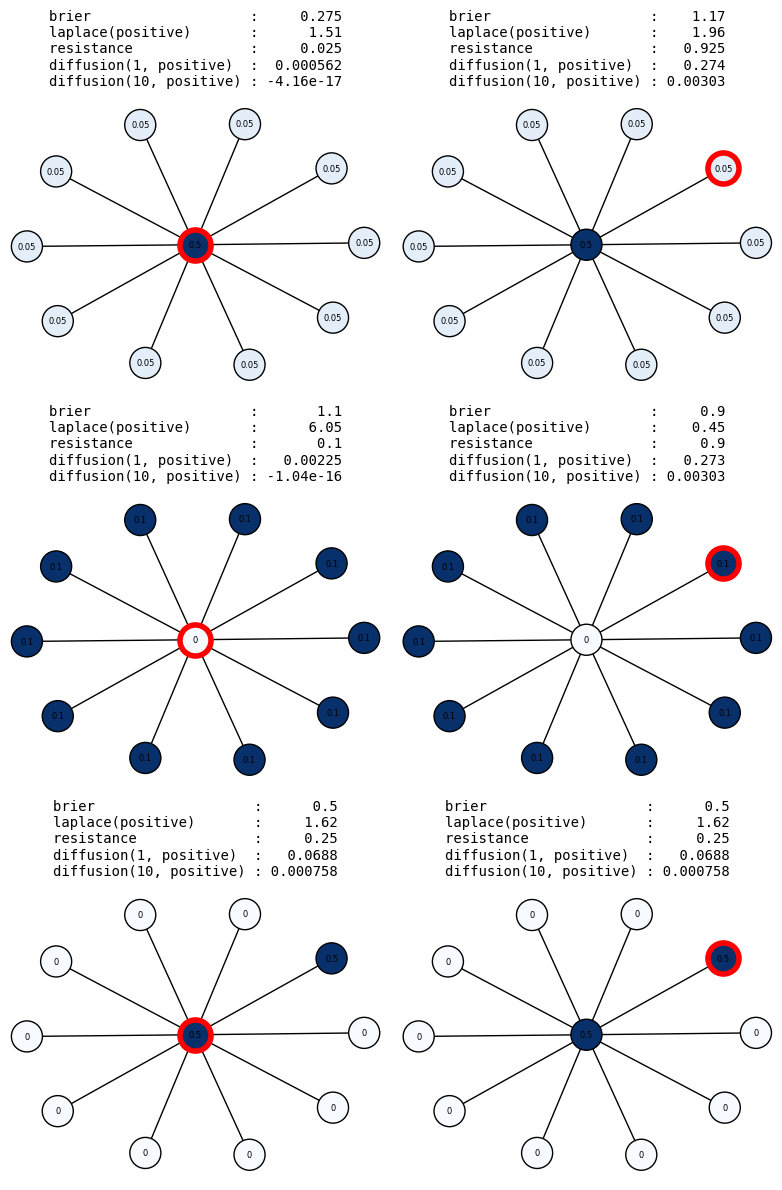

In [379]:
fig, axs = plt.subplots(3, 2, figsize=(8, 12), dpi=100)

for task, ax in zip([task_1a, task_1b, task_1c, task_1d, task_1e, task_1f], axs.flatten()):
    plot_task(
        ax, G, node_probs=task.node_probs, true_node=task.true_node, 
        labels="prob", colorbar=False, contrast=1, prob_color="Blues", true_color="red", 
        scores=[
            "brier", 
            {"laplace": {"convention": "positive"}}, 
            "resistance", 
            {"diffusion": {"kappa2": 1, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 10, "convention": "positive"}}
        ], 
        score_pos="top"
    )
    ax.set_axis_off()  # optional, already done in plot_task

plt.tight_layout()
plt.show()

## Example 2: Barbell graph

In [380]:
G = nx.barbell_graph(5, 2)

In [381]:
G.nodes()

NodeView((0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11))

In [382]:
G.edges()

EdgeView([(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (7, 9), (7, 10), (7, 11), (8, 9), (8, 10), (8, 11), (9, 10), (9, 11), (10, 11)])

In [383]:
adjacency_matrix = nx.to_numpy_array(G, weight=None)
adjacency_matrix

array([[0., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
       [1., 1., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
       [1., 1., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [1., 1., 1., 1., 0., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 1., 1., 1., 1.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 1., 1.],
       [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 1., 1.],
       [0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 1.],
       [0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 0.]])

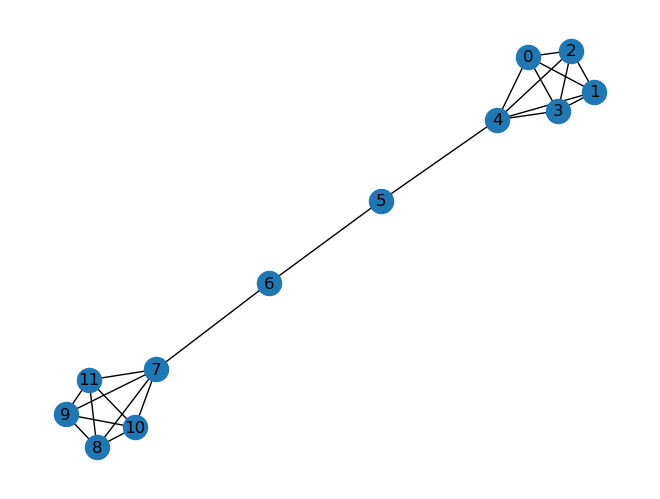

In [384]:
nx.draw(G, pos = nx.spring_layout(G), with_labels=True)

In [385]:
# Task 2a

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0:5] = 0.2
assert np.allclose(sum(prediction), 1)

task_2a = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [386]:
# Task 2b

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.2
prediction[1] = 0.3
prediction[2] = 0.15
prediction[4] = 0.1
prediction[5] = 0.1
prediction[6] = 0.05
prediction[7] = 0.1
assert np.allclose(sum(prediction), 1)

task_2b = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [387]:
# Task 2c

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[1] = 0.5
prediction[2] = 0.5
assert np.allclose(sum(prediction), 1)

task_2c = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [388]:
# Task 2d

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.2
prediction[1] = 0.15
prediction[2] = 0.1
prediction[3] = 0.1
prediction[4] = 0.1
prediction[5] = 0.05
prediction[6] = 0.05
prediction[7] = 0.05
prediction[8] = 0.05
prediction[9] = 0.05
prediction[10] = 0.05
prediction[11] = 0.05
assert np.allclose(sum(prediction), 1)

task_2d = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [389]:
# Task 2e

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.05
prediction[1] = 0.15
prediction[2] = 0.15
prediction[3] = 0.1
prediction[4] = 0.2
prediction[7] = 0.05
prediction[8] = 0.05
prediction[9] = 0.05
prediction[10] = 0.1
prediction[11] = 0.1
assert np.allclose(sum(prediction), 1)

task_2e = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [390]:
# Task 2e

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.05
prediction[4] = 0.1
prediction[5] = 0.1
prediction[6] = 0.05
prediction[7] = 0.05
prediction[8] = 0.1
prediction[9] = 0.1
prediction[10] = 0.25
prediction[11] = 0.2
assert np.allclose(sum(prediction), 1)

task_2e = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [391]:
# Task 2f

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.5
prediction[11] = 0.5
assert np.allclose(sum(prediction), 1)

task_2f = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

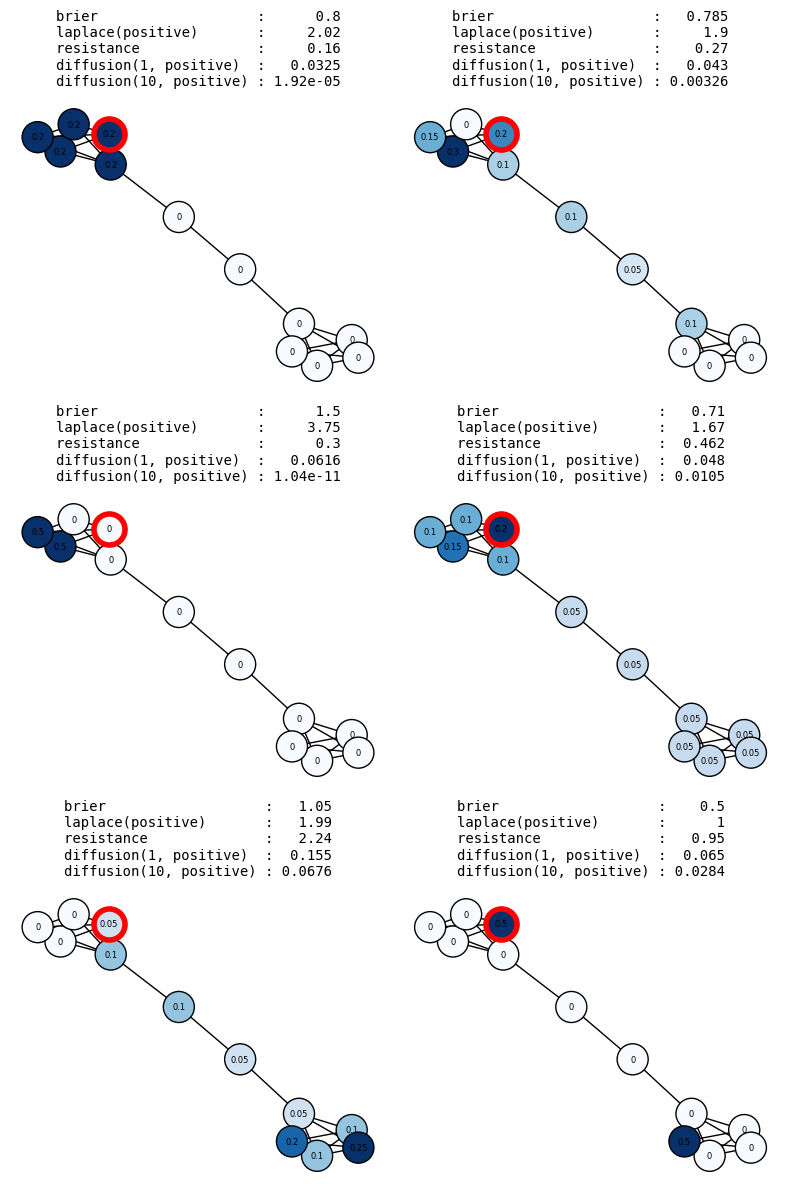

In [392]:
fig, axs = plt.subplots(3, 2, figsize=(8, 12), dpi=100)

for task, ax in zip([task_2a, task_2b, task_2c, task_2d, task_2e, task_2f], axs.flatten()):
    plot_task(
        ax, G, node_probs=task.node_probs, true_node=task.true_node, 
        labels="prob", colorbar=False, contrast=1, prob_color="Blues", true_color="red", 
        scores=[
            "brier", 
            {"laplace": {"convention": "positive"}}, 
            "resistance", 
            {"diffusion": {"kappa2": 1, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 10, "convention": "positive"}}
        ], 
        score_pos="top"
    )
    ax.set_axis_off()  # optional, already done in plot_task

plt.tight_layout()
plt.show()

# Network models

## Example 11: Erdös-Renyi

In [393]:
def connected_erdos_renyi_graph(n, p, seed=None, max_tries=1000):
    """Generate a connected Erdős–Rényi graph by retrying until connected."""
    rng = np.random.default_rng(seed)
    for _ in range(max_tries):
        G = nx.erdos_renyi_graph(n, p, seed=int(rng.integers(1e9)))
        if nx.is_connected(G):
            return G
    raise RuntimeError(f"Failed to generate a connected graph after {max_tries} tries.")

In [394]:
G = connected_erdos_renyi_graph(30, 0.1, seed=42)
adjacency_matrix = nx.to_numpy_array(G, weight=None)

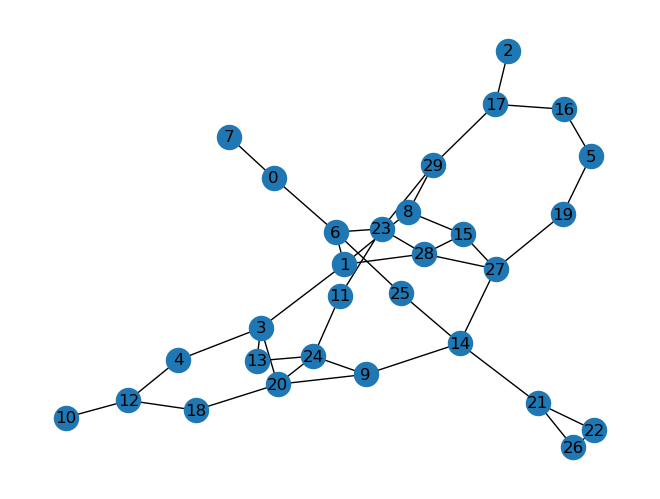

In [395]:
nx.draw(G, pos = nx.spring_layout(G), with_labels=True)

In [396]:
# Task 11a

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.1
prediction[7] = 0.1
prediction[6] = 0.1
prediction[1] = 0.1
prediction[23] = 0.1
prediction[25] = 0.1
prediction[28] = 0.1
prediction[3] = 0.1
prediction[8] = 0.1
prediction[15] = 0.1

assert np.allclose(sum(prediction), 1)

task_11a = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [397]:
# Task 11b

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.1
prediction[7] = 0.1
prediction[6] = 0.1
prediction[1] = 0.1
prediction[23] = 0.1
prediction[25] = 0.1
prediction[28] = 0.1
prediction[26] = 0.1
prediction[2] = 0.1
prediction[10] = 0.1

assert np.allclose(sum(prediction), 1)

task_11b = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [398]:
# Task 11c

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.2
prediction[7] = 0.2
prediction[6] = 0.2
prediction[1] = 0.2
prediction[23] = 0.2


assert np.allclose(sum(prediction), 1)

task_11c = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [399]:
# Task 11d

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.2
prediction[6] = 0.2
prediction[1] = 0.2
prediction[23] = 0.2
prediction[8] = 0.2

assert np.allclose(sum(prediction), 1)

task_11d = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [400]:
# Task 11e

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.6
prediction[7] = 0.2
prediction[6] = 0.2

assert np.allclose(sum(prediction), 1)

task_11e = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [401]:
# Task 11f

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.2
prediction[6] = 0.6
prediction[1] = 0.1
prediction[23] = 0.05
prediction[25] = 0.05

assert np.allclose(sum(prediction), 1)

task_11f = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

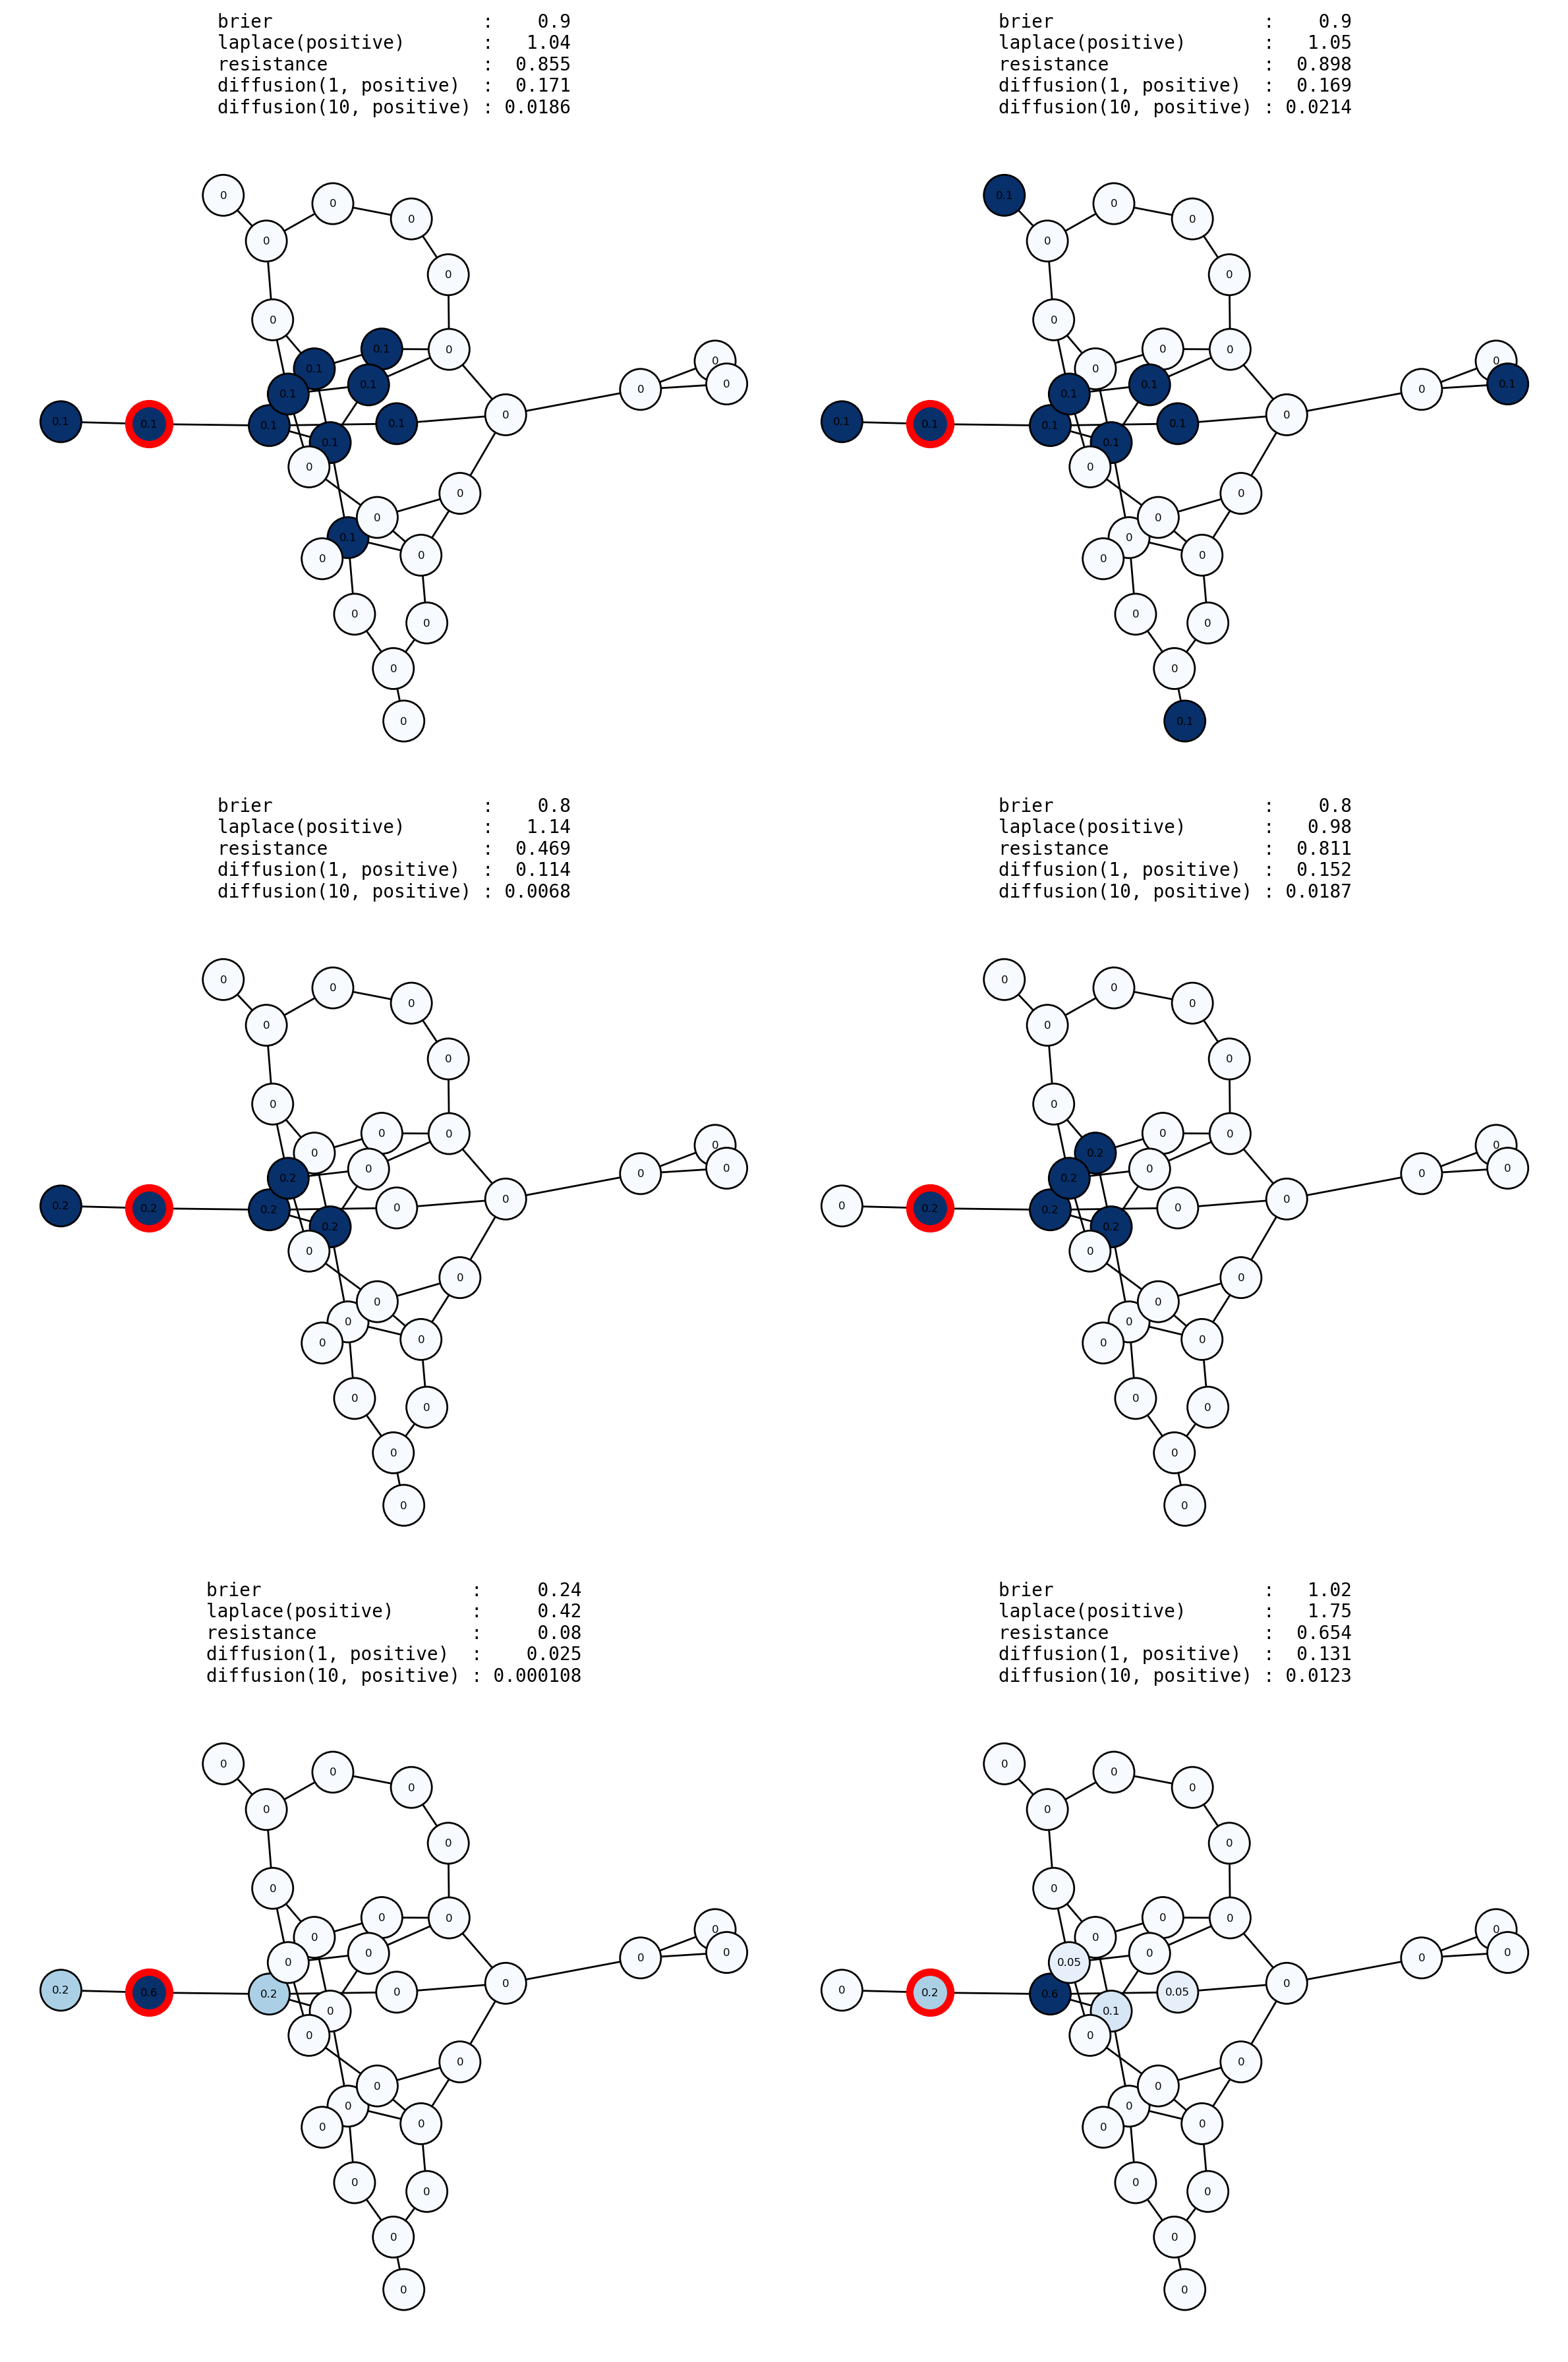

In [402]:
fig, axs = plt.subplots(3, 2, figsize=(12, 18), dpi=200)

for task, ax in zip([task_11a, task_11b, task_11c, task_11d, task_11e, task_11f], axs.flatten()):
    plot_task(
        ax, G, node_probs=task.node_probs, true_node=task.true_node, 
        labels="prob", colorbar=False, contrast=1, prob_color="Blues", true_color="red", 
        scores=[
            "brier", 
            {"laplace": {"convention": "positive"}}, 
            "resistance", 
            {"diffusion": {"kappa2": 1, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 10, "convention": "positive"}}
        ], 
        score_pos="top"
    )
    ax.set_axis_off()  # optional, already done in plot_task

plt.tight_layout()
plt.show()

## Example 12: Stochastic Block Model

In [403]:
def connected_sbm(s, p, seed=None, max_tries=1000):
    """Generate a connected Stochastic Block Model graph by retrying until connected."""
    rng = np.random.default_rng(seed)
    for _ in range(max_tries):
        G = nx.stochastic_block_model(s, p, seed=int(rng.integers(1e9)))
        if nx.is_connected(G):
            return G
    raise RuntimeError(f"Failed to generate a connected graph after {max_tries} tries.")

In [404]:
s = [5, 7, 7]
p = [[0.5, 0.04, 0.03], [0.04, 0.4, 0.01], [0.03, 0.01, 0.4]]  # must be symmetric
G = connected_sbm(s, p, seed=42)
adjacency_matrix = nx.to_numpy_array(G, weight=None)
adjacency_matrix

array([[0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        1., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [1., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 1., 1., 0., 1., 1., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 0., 1., 0., 0., 0., 0.

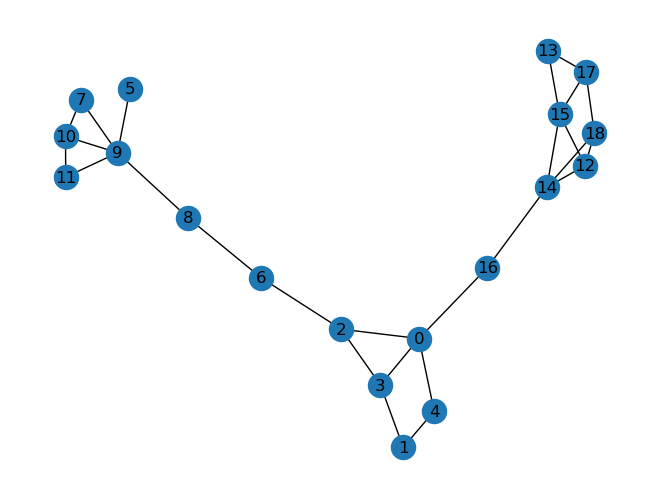

In [405]:
nx.draw(G, pos = nx.spring_layout(G), with_labels=True)

In [406]:
# Task 12a

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[5] = 0.1
prediction[7] = 0.1
prediction[9] = 0.2
prediction[10] = 0.5
prediction[11] = 0.1

assert np.allclose(sum(prediction), 1)

task_12a = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [407]:
# Task 12b (good prediction)

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[2] = 0.1
prediction[6] = 0.1
prediction[9] = 0.5
prediction[10] = 0.2
prediction[8] = 0.1

assert np.allclose(sum(prediction), 1)

task_12b = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [408]:
# Task 12b (miscalibrated)

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[2] = 0.1
prediction[6] = 0.1
prediction[9] = 0.5
prediction[10] = 0.2
prediction[8] = 0.1

assert np.allclose(sum(prediction), 1)

task_12b = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [409]:
# Task 12c (even more miscalibrated)

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[2] = 0.1
prediction[6] = 0.2
prediction[9] = 0.3
prediction[10] = 0.2
prediction[8] = 0.2

assert np.allclose(sum(prediction), 1)

task_12c = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [410]:
# Task 12d (probability uniformly spread across correct cluster)

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[5] = 0.2
prediction[7] = 0.2
prediction[9] = 0.2
prediction[10] = 0.2
prediction[11] = 0.2

assert np.allclose(sum(prediction), 1)

task_12d = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [411]:
# Task 12e (probability uniformly spread across neighbouring cluster)

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.2
prediction[1] = 0.2
prediction[2] = 0.2
prediction[3] = 0.2
prediction[4] = 0.2

assert np.allclose(sum(prediction), 1)

task_12e = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [412]:
# Task 12f (probability uniformly spread across faraway cluster)

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[12] = 0.2
prediction[13] = 0.2
prediction[14] = 0.2
prediction[15] = 0.2
prediction[16] = 0.2

assert np.allclose(sum(prediction), 1)

task_12f = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [413]:
# Task 12g (probability in correct cluster, but on wrong nodes, sharper than previous version)

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[7] = 0.3
prediction[9] = 0.4
prediction[11] = 0.3
assert np.allclose(sum(prediction), 1)

task_12g = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [414]:
# Task 12h (probability in correct cluster, but on wrong nodes)

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[5] = 0.3
prediction[7] = 0.2
prediction[9] = 0.2
prediction[11] = 0.3

assert np.allclose(sum(prediction), 1)

task_12h = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [415]:
# Task 12i (atomic drops of probability in cluster centers)

# Ground truth
true_node = 10

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.3
prediction[12] = 0.2
prediction[9] = 0.2
prediction[11] = 0.3

assert np.allclose(sum(prediction), 1)

task_12i = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

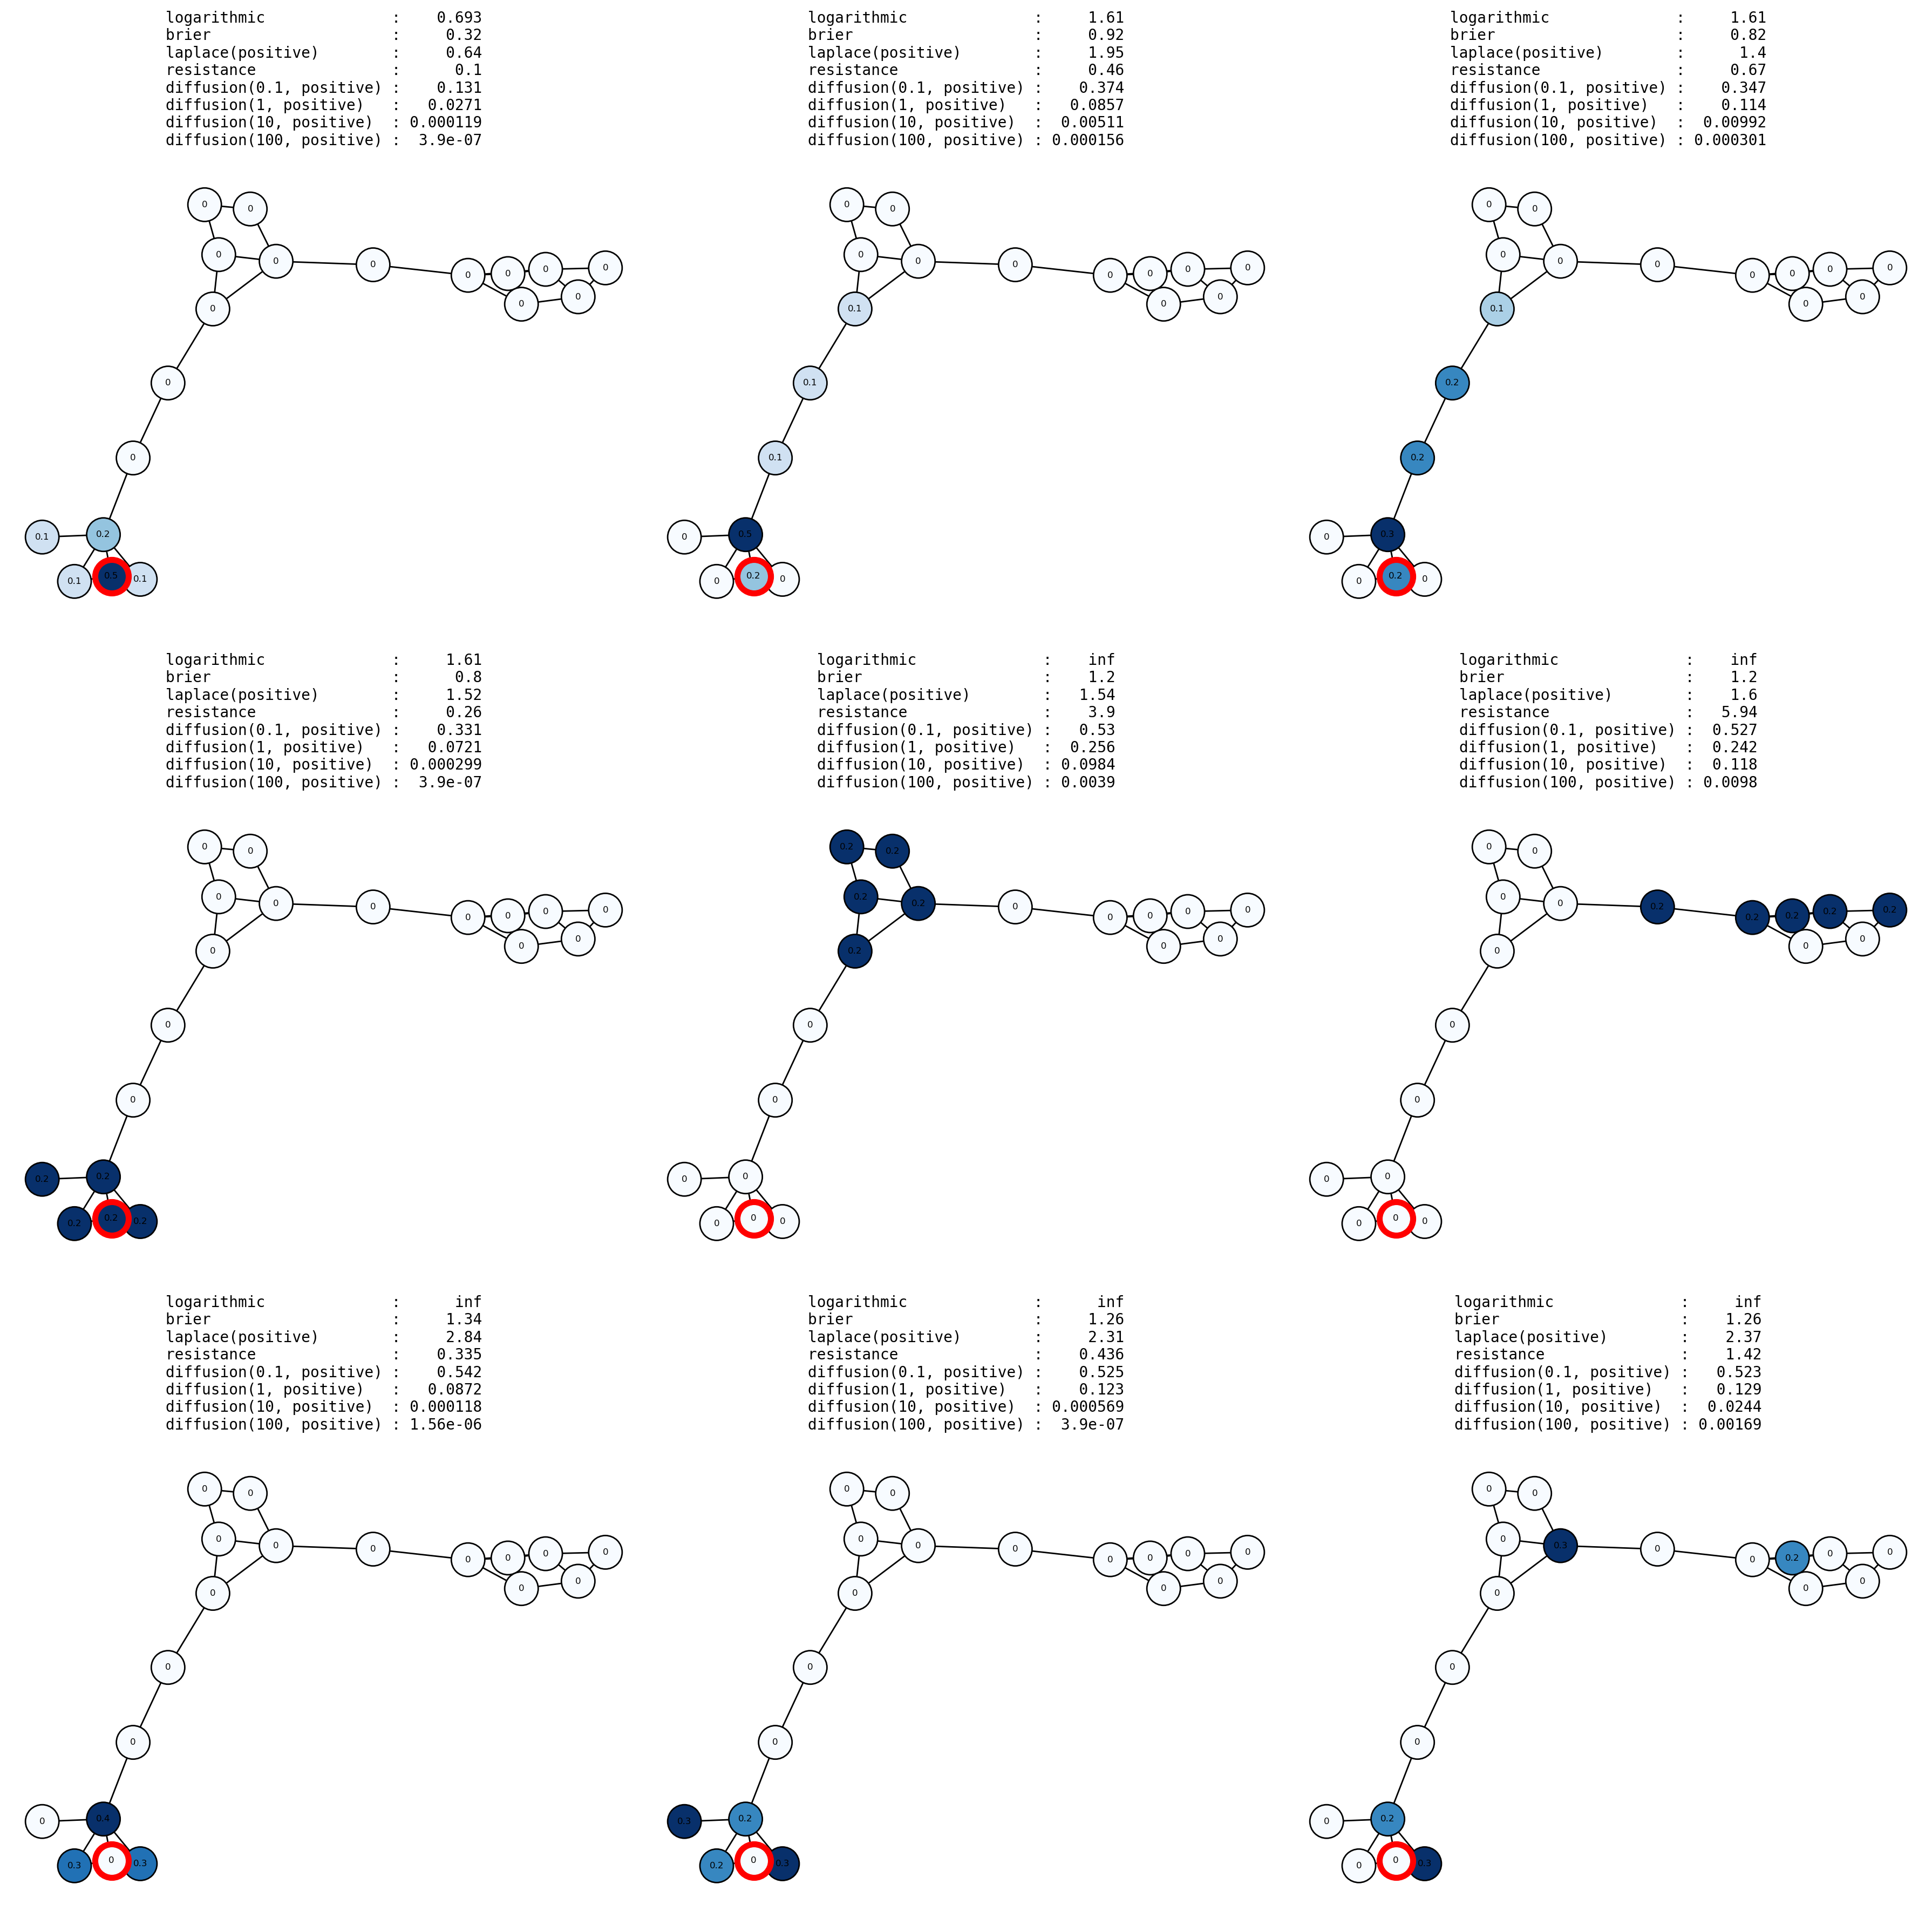

In [416]:
fig, axs = plt.subplots(3, 3, figsize=(18, 18), dpi=200)

for task, ax in zip([task_12a, task_12b, task_12c, task_12d, task_12e, task_12f, task_12g, task_12h, task_12i], axs.flatten()):
    plot_task(
        ax, G, node_probs=task.node_probs, true_node=task.true_node, 
        labels="prob", colorbar=False, contrast=1, prob_color="Blues", true_color="red", 
        scores=[
            "logarithmic",
            "brier", 
            {"laplace": {"convention": "positive"}}, 
            "resistance", 
            {"diffusion": {"kappa2": 0.1, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 1, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 10, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 100, "convention": "positive"}}
        ], 
        score_pos="top"
    )
    ax.set_axis_off()  # optional, already done in plot_task

plt.tight_layout()
plt.show()